In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D
import cv2
from scipy.optimize import linear_sum_assignment
from skimage.measure import label
import OptimusPrimus as OP

SEG_MODEL = "Data/models/seg_Training-obsidian_n59-9f0fcd_MAnet-efficientnet-b7_ep200-bs2-lr3e-04-Dice-F1"
CLS_MODEL = os.path.join(SEG_MODEL, "seg_Training-obsidian_n59-9f0fcd_MAnet-efficientnet-b7_ep200-bs2-lr3e-04-Dice-F1"
                                    "__cls-auto_pt0.1_efficientnet-b0_ep80-bs64-lr3e-05-pw0.7.pth")
CLS_TH = None            # None: operating point stored with the classifier (0.55)
TILE = None              # None: median val/test tile by F1; or a file name, e.g. "Acquisition_2793_0_0.png"
ZOOM = None              # None: chosen automatically; or (x0, y0) of the zoom window [px]
ZOOM_SIZE = 256          # zoom window side [px]
OUT = "figures/optimusprimus_validation_output"   # .pdf and .png are written

# Okabe-Ito colours (colour-blind safe); annotations differ from detections also by mark type (outline vs fill)
C_ANN, C_TP, C_FP, C_REJ = "#F0E442", "#009E73", "#D55E00", "#56B4E9"

In [2]:
seg_pth, seg_rec = OP.resolve_seg_model(SEG_MODEL)
cls_pth, cls_rec = OP.resolve_cls_model(CLS_MODEL, seg_rec)
seg_th, cls_th = seg_rec['threshold'], (cls_rec['threshold'] if CLS_TH is None else CLS_TH)
um = seg_rec['image_config']['pixel_resolution_um_per_px']
device = OP._device()
seg_net, prep = OP._load_seg(seg_pth, seg_rec, device)
cls_net = OP._load_cls(cls_pth, cls_rec, device)
transform = OP.get_class_transform()


def match(gt_mask, pred_mask):
    # Same matching as the descriptor (ellipse-contour instances, Hungarian, IoU >= OP.IOU_THRESHOLD).
    gt, pred = OP.extract_instances(gt_mask, um), OP.extract_instances(pred_mask, um)
    gt_hit, pred_hit = np.zeros(len(gt), bool), np.zeros(len(pred), bool)
    if gt and pred:
        iou = np.array([[OP._instance_iou(g, p) for p in pred] for g in gt])
        for i, j in zip(*linear_sum_assignment(-iou)):
            if iou[i, j] >= OP.IOU_THRESHOLD:
                gt_hit[i] = pred_hit[j] = True
    return gt, gt_hit, pred, pred_hit


def paint(instances, flags, shape):
    # Label image: 1 = matched, 2 = unmatched.
    out = np.zeros(shape, np.uint8)
    for inst, hit in zip(instances, flags):
        x, y, w, h = inst['bbox']
        out[y:y + h, x:x + w][inst['mask']] = 1 if hit else 2
    return out


tiles = []
for img_path, mask_path in seg_rec['split']['val'] + seg_rec['split']['test']:
    gt_mask = (cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 0).astype(np.uint8)
    image, seg_mask = OP.predict_seg_mask(img_path, seg_net, prep, device, seg_th)
    cls_mask = OP.create_class_mask(image, seg_mask, cls_net, transform, device, cls_th)
    gt, gt_hit_s, pred_s, hit_s = match(gt_mask, seg_mask)
    _, gt_hit_c, pred_c, hit_c = match(gt_mask, cls_mask)
    tp, fp, fn = hit_c.sum(), (~hit_c).sum(), (~gt_hit_c).sum()
    tiles.append(dict(name=os.path.basename(img_path), image=image, gt=gt_mask,
                      seg=paint(pred_s, hit_s, gt_mask.shape), cls=paint(pred_c, hit_c, gt_mask.shape),
                      rejected=(seg_mask > 0) & (cls_mask == 0),
                      n_ann=len(gt), seg_tp=hit_s.sum(), seg_fp=(~hit_s).sum(), tp=tp, fp=fp, fn=fn,
                      f1=2 * tp / max(2 * tp + fp + fn, 1)))

summary = pd.DataFrame([{k: t[k] for k in ('name', 'n_ann', 'seg_tp', 'seg_fp', 'tp', 'fp', 'fn', 'f1')} for t in tiles])
summary.sort_values('f1')

,name,n_ann,seg_tp,seg_fp,tp,fp,fn,f1
11,Acquisition_2429_3_0.png,41,13,8,12,7,29,0.400000
0,Acquisition_2475_0_0.png,70,36,15,33,12,37,0.573913
12,Acquisition_2793_1_1.png,41,22,13,21,8,20,0.600000
2,Acquisition_2429_0_0.png,36,19,10,19,8,17,0.603175
5,Acquisition_2793_3_1.png,39,19,8,19,5,20,0.603175
4,Acquisition_2475_3_1.png,83,44,14,42,10,41,0.622222
7,Acquisition_2873_1_0.png,52,27,6,26,4,26,0.634146
6,Acquisition_2793_1_0.png,20,14,13,13,7,7,0.650000
1,Acquisition_2793_0_0.png,26,18,10,18,10,8,0.666667
10,Acquisition_2635_2_0.png,54,41,21,41,17,13,0.732143


In [13]:
TILE = "Acquisition_2635_2_0.png"

if TILE is None:
    order = summary.sort_values('f1').index
    t = tiles[order[len(order) // 2]]                      # median F1: representative, not the best case
else:
    t = next(x for x in tiles if x['name'] == TILE)

H, W = t['gt'].shape

ZOOM = 275, 275
if ZOOM is None:                                           # window with the richest mix of outcomes
    best, ZOOM = -1, (0, 0)
    for y0 in range(0, H - ZOOM_SIZE + 1, 32):
        for x0 in range(0, W - ZOOM_SIZE + 1, 32):
            sl = np.s_[y0:y0 + ZOOM_SIZE, x0:x0 + ZOOM_SIZE]
            parts = [label(t['cls'][sl] == 1).max(), label(t['cls'][sl] == 2).max(),
                     label(t['rejected'][sl]).max(), label(t['gt'][sl] & (t['cls'][sl] == 0)).max()]
            score = 100 * sum(p > 0 for p in parts) + sum(parts)
            if score > best:
                best, ZOOM = score, (x0, y0)
print(f"tile {t['name']}: {t['n_ann']} annotated | segmentation {t['seg_tp']} matched + {t['seg_fp']} unmatched | "
      f"classifier {t['tp']} matched + {t['fp']} unmatched, {t['fn']} missed (F1 {t['f1']:.2f}) | zoom at {ZOOM}")

tile Acquisition_2635_2_0.png: 54 annotated | segmentation 41 matched + 21 unmatched | classifier 41 matched + 17 unmatched, 13 missed (F1 0.73) | zoom at (275, 275)


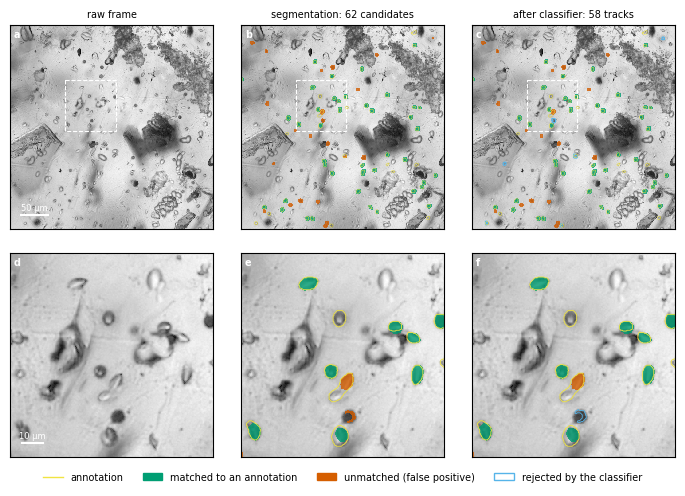

In [14]:
def overlay(ax, label_img, rejected=None, alpha=0.8, grow=0):
    if grow:                                               # display only: thicken objects in the full-frame row
        k = np.ones((grow, grow), np.uint8)
        label_img = np.maximum(cv2.dilate((label_img == 1).astype(np.uint8), k),
                               2 * cv2.dilate((label_img == 2).astype(np.uint8), k) * (label_img != 1))
        rejected = None if rejected is None else cv2.dilate(rejected.astype(np.uint8), k) > 0
    rgba = np.zeros(label_img.shape + (4,))
    for value, colour in ((1, C_TP), (2, C_FP)):
        rgba[label_img == value] = (*plt.matplotlib.colors.to_rgb(colour), alpha)
    ax.imshow(rgba, interpolation='nearest')


def scalebar(ax, length_um, x0, y0, span):
    px = length_um / um
    ax.plot([x0, x0 + px], [y0, y0], color='white', lw=1.5, solid_capstyle='butt')
    ax.text(x0 + px / 2, y0 - 0.015 * span, f"{length_um:g} µm", color='white', ha='center', va='bottom', fontsize=6)


x0, y0 = ZOOM
zoom = np.s_[y0:y0 + ZOOM_SIZE, x0:x0 + ZOOM_SIZE]
gray = cv2.cvtColor(t['image'], cv2.COLOR_RGB2GRAY)
plt.rcParams.update({'font.size': 7, 'axes.titlesize': 7})
fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.9), gridspec_kw=dict(hspace=0.12, wspace=0.03))
titles = ["raw frame",
          f"segmentation: {t['seg_tp'] + t['seg_fp']} candidates",
          f"after classifier: {t['tp'] + t['fp']} tracks"]
for row, sl in enumerate((np.s_[:, :], zoom)):
    span = gray[sl].shape[0]
    for col in range(3):
        ax = axes[row, col]
        ax.imshow(gray[sl], cmap='gray', interpolation='nearest')
        if col == 1:
            overlay(ax, t['seg'][sl], grow=0 if row else 7)
        if col == 2:
            overlay(ax, t['cls'][sl], grow=0 if row else 7)
            rej = t['rejected'][sl].astype(np.uint8)
            if row == 0:
                rej = cv2.dilate(rej, np.ones((7, 7), np.uint8))
            ax.contour(rej, levels=[0.5], colors=C_REJ, linewidths=0.6 if row else 0.8)
        if col > 0:
            ax.contour(t['gt'][sl], levels=[0.5], colors=C_ANN, linewidths=0.6 if row else 0.35)
        if row == 0:
            ax.set_title(titles[col])
            ax.add_patch(Rectangle((x0, y0), ZOOM_SIZE, ZOOM_SIZE, fill=False, ec='white', lw=0.8, ls='--'))
        if col == 0:
            scalebar(ax, 50 if row == 0 else 10, 0.05 * span, 0.93 * span, span)
        ax.text(0.02, 0.98, "abcdef"[3 * row + col], transform=ax.transAxes, color='white',
                fontweight='bold', va='top', ha='left')
        ax.set_xticks([]); ax.set_yticks([])

handles = [Line2D([], [], color=C_ANN, lw=1, label='annotation'),
           Patch(color=C_TP, label='matched to an annotation'),
           Patch(color=C_FP, label='unmatched (false positive)'),
           Patch(facecolor='none', edgecolor=C_REJ, lw=1, label='rejected by the classifier')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.07)
os.makedirs(os.path.dirname(OUT) or ".", exist_ok=True)
fig.savefig(OUT + ".pdf")
fig.savefig(OUT + ".png", dpi=300)
plt.show()